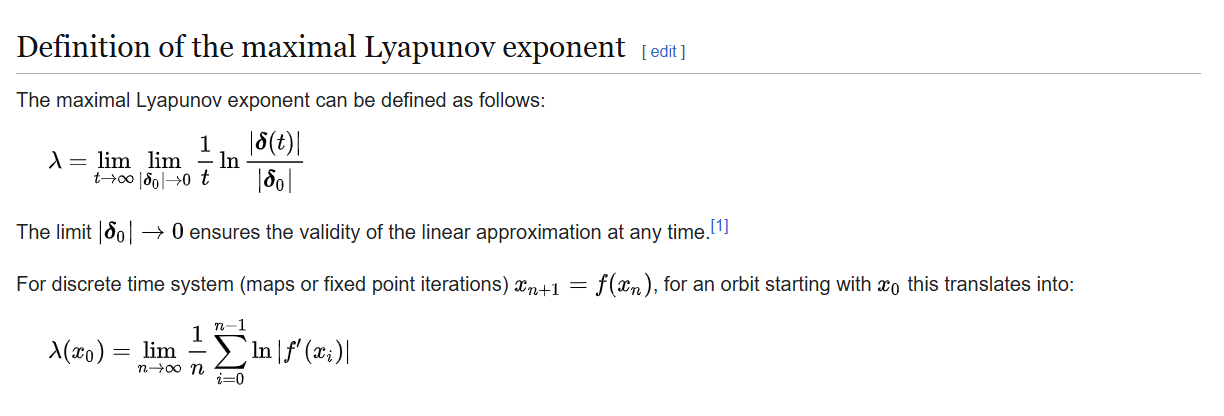

WHAT SIR SAID:

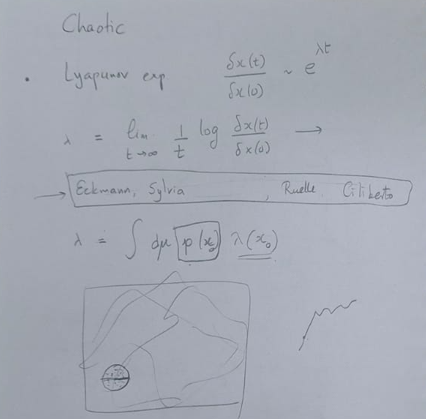

In [1]:
# CELL 1: Import Libraries
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt


In [16]:

# CELL 2: Define Lyapunov Exponent Function
def lyapunov_exponent(data, m=3, tau=1):
    """Calculate largest Lyapunov exponent"""
    n = len(data) - m * tau
    lyap_sum = 0
    count = 0
    
    for i in range(n - 1):
        state_i = data[i:i + m * tau:tau]
        state_next = data[i + 1:i + 1 + m * tau:tau]
        
        # Find nearest neighbor
        min_dist = float('inf')
        for j in range(n - 1):
            if abs(i - j) > tau:
                state_j = data[j:j + m * tau:tau]
                dist = np.linalg.norm(state_i - state_j)
                if dist < min_dist and dist > 0:
                    min_dist = dist
                    neighbor_next = data[j + 1:j + 1 + m * tau:tau]
        
        if min_dist < float('inf'):
            dist_evolved = np.linalg.norm(state_next - neighbor_next)
            if dist_evolved > 0 and min_dist > 0:
                lyap_sum += np.log(dist_evolved / min_dist)
                count += 1
    
    return lyap_sum / count if count > 0 else 0

def interpret(lambda_exp):
    if lambda_exp > 0:
        return "CHAOTIC - Sensitive to initial conditions"
    elif lambda_exp < -0.01:
        return "STABLE - Converges to equilibrium"
    else:
        return "NEUTRAL - Periodic/marginal behavior"


In [17]:
# CELL 3: Download Stock Data
ticker = "AAPL"  # Change to any stock: TSLA, GOOGL, MSFT, etc.
stock = yf.download(ticker, period="5y", progress=False)
prices = stock['Close'].values
returns = np.log(prices[1:] / prices[:-1])

print(f"Downloaded {len(prices)} days of data for {ticker}")


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\2245528281.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="5y", progress=False)


Downloaded 1256 days of data for AAPL


In [18]:
# CELL 4: Calculate Lyapunov Exponents
lambda_price = lyapunov_exponent(prices)
lambda_returns = lyapunov_exponent(returns)

print(f"\nStock: {ticker}")
print(f"\n{'='*50}")
print("PRICE SERIES:")
print(f"  Lyapunov Exponent (λ): {lambda_price:.4f}")
print(f"  → {interpret(lambda_price)}")

print(f"\n{'='*50}")
print("RETURNS SERIES:")
print(f"  Lyapunov Exponent (λ): {lambda_returns:.4f}")
print(f"  → {interpret(lambda_returns)}")



Stock: AAPL

PRICE SERIES:
  Lyapunov Exponent (λ): 0.8383
  → CHAOTIC - Sensitive to initial conditions

RETURNS SERIES:
  Lyapunov Exponent (λ): 1.4503
  → CHAOTIC - Sensitive to initial conditions


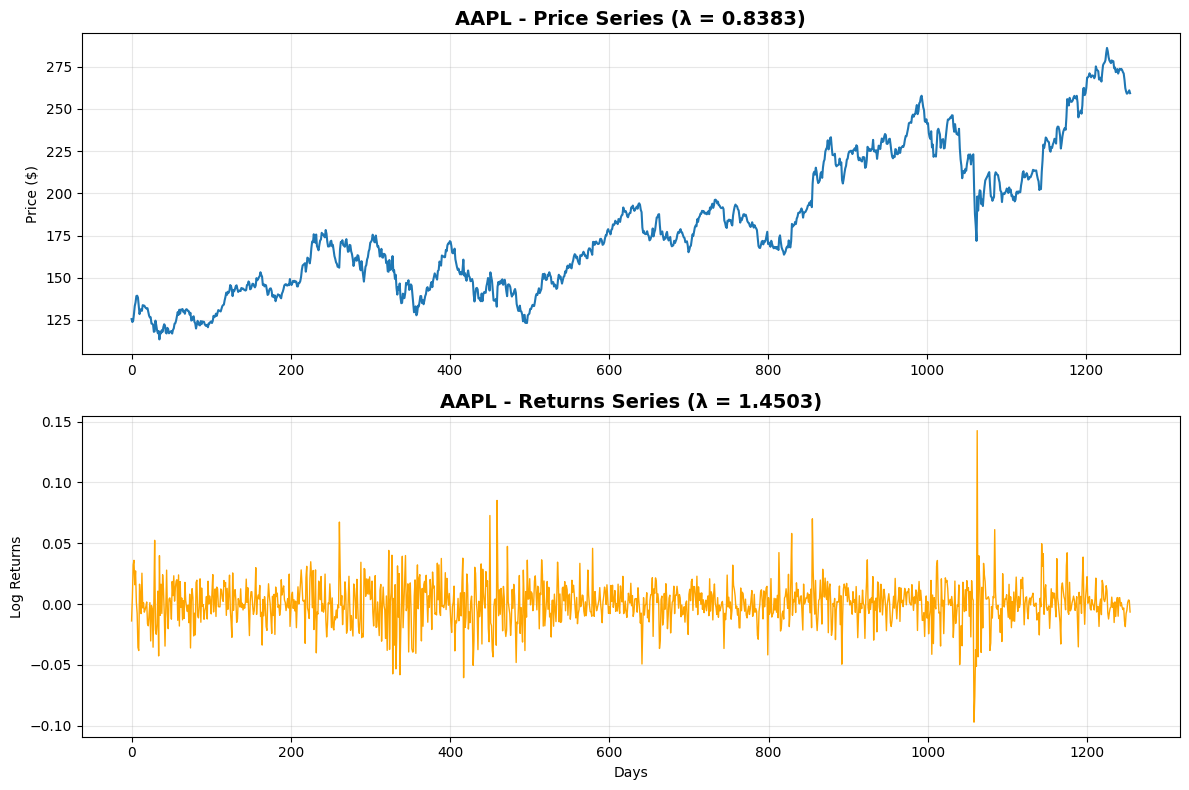

In [19]:
# CELL 5: Visualize Data
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(prices, linewidth=1.5)
axes[0].set_title(f'{ticker} - Price Series (λ = {lambda_price:.4f})', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Price ($)')
axes[0].grid(alpha=0.3)

axes[1].plot(returns, linewidth=1, color='orange')
axes[1].set_title(f'{ticker} - Returns Series (λ = {lambda_returns:.4f})', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Log Returns')
axes[1].set_xlabel('Days')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
def compute_log_divergence(data, max_k=50):
    """Compute average log divergence vs time step k"""
    n = len(data)
    k_steps = range(1, max_k + 1)
    avg_log_div = []
    
    for k in k_steps:
        log_divs = []
        for i in range(n - k - 1):
            # Find nearest neighbor
            min_dist = float('inf')
            for j in range(n - k - 1):
                if abs(i - j) > 10:  # Avoid temporal correlation
                    dist = abs(data[i] - data[j])
                    if dist < min_dist and dist > 0:
                        min_dist = dist
                        j_nearest = j
            
            if min_dist < float('inf'):
                # Measure divergence after k steps
                dist_k = abs(data[i + k] - data[j_nearest + k])
                if dist_k > 0 and min_dist > 0:
                    log_divs.append(np.log(dist_k / min_dist))
        
        if log_divs:
            avg_log_div.append(np.mean(log_divs))
        else:
            avg_log_div.append(0)
    
    return list(k_steps), avg_log_div


In [7]:
ticker = "AAPL"  # Change to any stock
stock = yf.download(ticker, period="1y", progress=False)
prices = stock['Close'].values
returns = np.log(prices[1:] / prices[:-1])

print(f"Downloaded {len(prices)} days of data for {ticker}")

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\703322715.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Downloaded 252 days of data for AAPL


In [20]:
ticker = "AAPL"  # Change to any stock
stock = yf.download(ticker, period="1y", progress=False)
prices = stock['Close'].values
returns = np.log(prices[1:] / prices[:-1])

print(f"Downloaded {len(prices)} days of data for {ticker}")

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\703322715.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Downloaded 252 days of data for AAPL


In [21]:
# CELL 4: Calculate Divergence for Prices
k_vals_price, log_div_price = compute_log_divergence(prices, max_k=50)
slope_price = np.polyfit(k_vals_price[:20], log_div_price[:20], 1)[0]
print(f"\nPRICES - Lyapunov Exponent (slope): {slope_price:.4f}")


PRICES - Lyapunov Exponent (slope): 0.0467


In [22]:
# CELL 5: Calculate Divergence for Returns
k_vals_ret, log_div_ret = compute_log_divergence(returns, max_k=50)
slope_ret = np.polyfit(k_vals_ret[:20], log_div_ret[:20], 1)[0]
print(f"RETURNS - Lyapunov Exponent (slope): {slope_ret:.4f}")

RETURNS - Lyapunov Exponent (slope): -0.0078


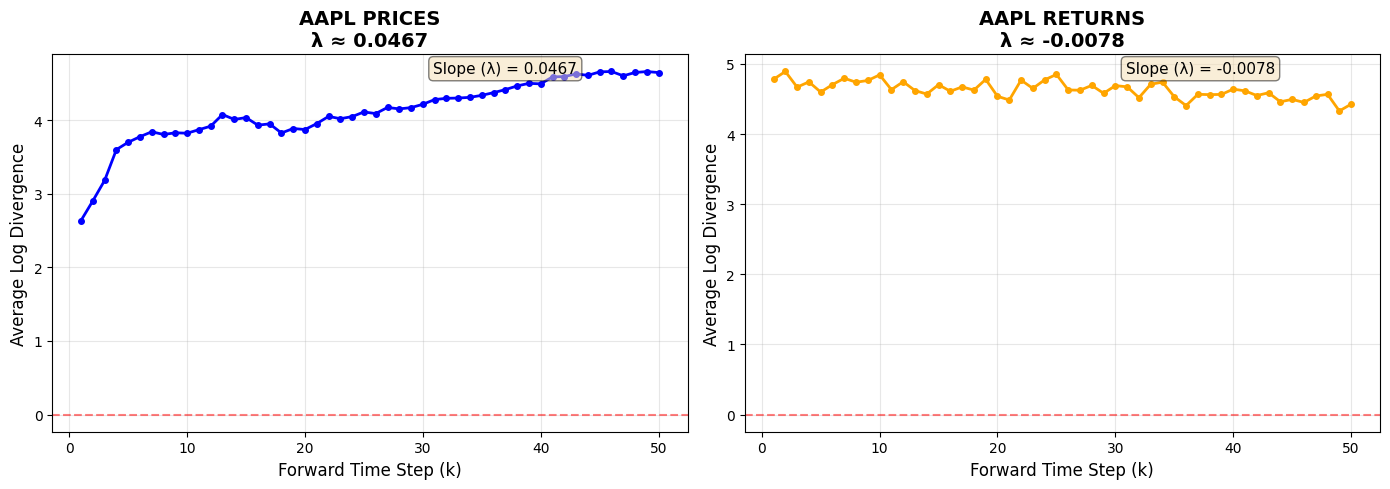

In [23]:
# CELL 6: Plot Average Log Divergence vs k
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot for Prices
axes[0].plot(k_vals_price, log_div_price, 'b-o', linewidth=2, markersize=4)
axes[0].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[0].set_xlabel('Forward Time Step (k)', fontsize=12)
axes[0].set_ylabel('Average Log Divergence', fontsize=12)
axes[0].set_title(f'{ticker} PRICES\nλ ≈ {slope_price:.4f}', fontsize=14, fontweight='bold')
axes[0].grid(alpha=0.3)
axes[0].text(0.6, 0.95, f'Slope (λ) = {slope_price:.4f}', 
             transform=axes[0].transAxes, fontsize=11, 
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Plot for Returns
axes[1].plot(k_vals_ret, log_div_ret, 'orange', marker='o', linewidth=2, markersize=4)
axes[1].axhline(y=0, color='r', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Forward Time Step (k)', fontsize=12)
axes[1].set_ylabel('Average Log Divergence', fontsize=12)
axes[1].set_title(f'{ticker} RETURNS\nλ ≈ {slope_ret:.4f}', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3)
axes[1].text(0.6, 0.95, f'Slope (λ) = {slope_ret:.4f}', 
             transform=axes[1].transAxes, fontsize=11,
             bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

They're the Same Thing - Just Different Representations

Lyapunov Exponent (λ) = Rate at which nearby trajectories diverge

Log Divergence = The actual divergence measured at each time step k

Analyzing AAPL...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Analyzing TSLA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Analyzing GOOGL...


...

Analyzing NVDA...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)


Analyzing AMZN...


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_20724\1845703607.py:43: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock = yf.download(ticker, period="1y", progress=False)



LYAPUNOV EXPONENT SUMMARY
Ticker λ_prices λ_returns Price_Status Return_Status
  AAPL   0.0467   -0.0078      CHAOTIC        STABLE
  TSLA   0.0696   -0.0020      CHAOTIC        STABLE
 GOOGL   0.0740   -0.0027      CHAOTIC        STABLE
  MSFT   0.0515   -0.0088      CHAOTIC        STABLE
  NVDA   0.0431   -0.0101      CHAOTIC        STABLE
  AMZN   0.0531   -0.0072      CHAOTIC        STABLE


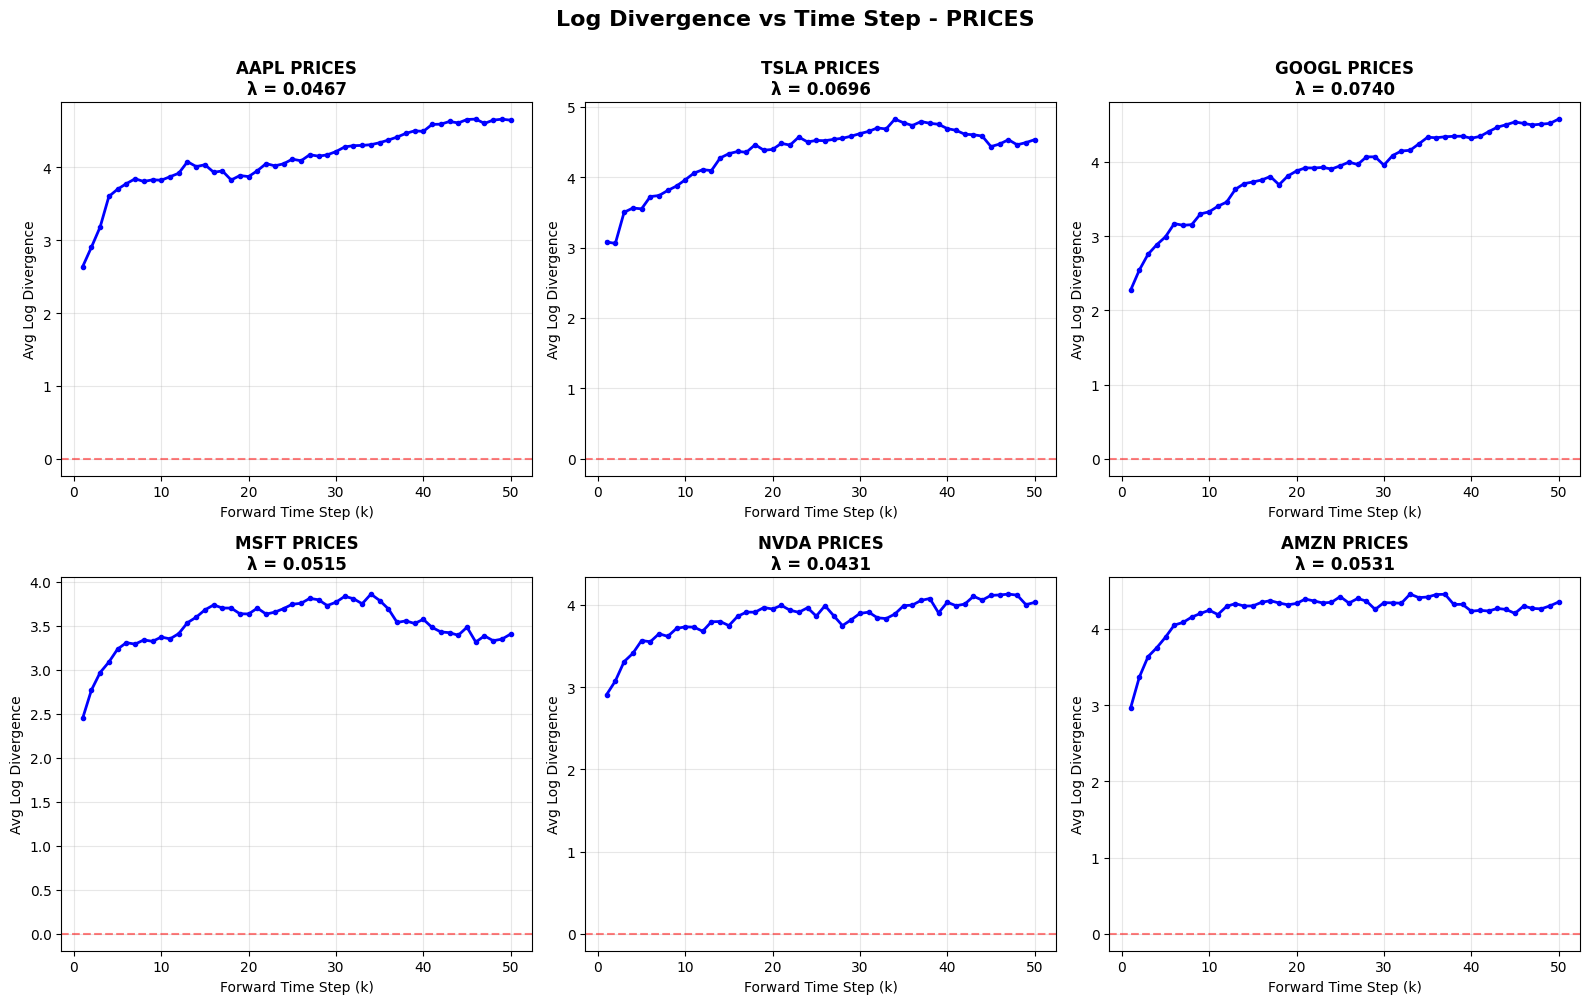

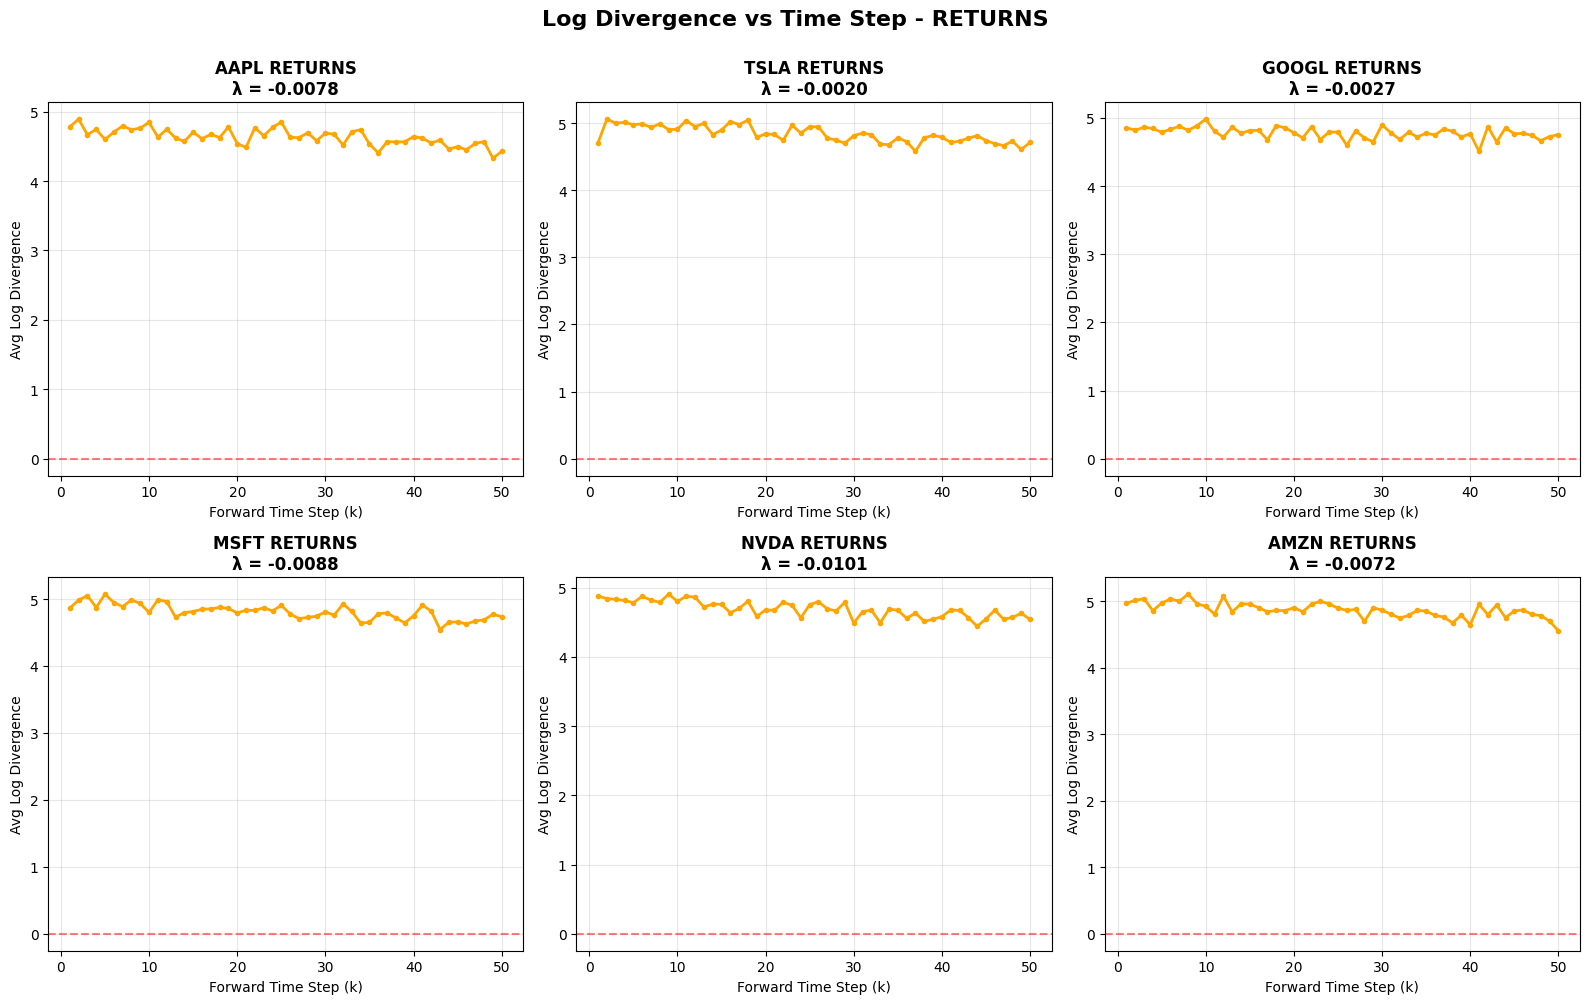

In [24]:
# CELL 1: Import Libraries
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# CELL 2: Define Log Divergence Function
def compute_log_divergence(data, max_k=50):
    """Compute average log divergence vs time step k"""
    n = len(data)
    k_steps = range(1, max_k + 1)
    avg_log_div = []
    
    for k in k_steps:
        log_divs = []
        for i in range(n - k - 1):
            min_dist = float('inf')
            for j in range(n - k - 1):
                if abs(i - j) > 10:
                    dist = abs(data[i] - data[j])
                    if dist < min_dist and dist > 0:
                        min_dist = dist
                        j_nearest = j
            
            if min_dist < float('inf'):
                dist_k = abs(data[i + k] - data[j_nearest + k])
                if dist_k > 0 and min_dist > 0:
                    log_divs.append(np.log(dist_k / min_dist))
        
        if log_divs:
            avg_log_div.append(np.mean(log_divs))
        else:
            avg_log_div.append(0)
    
    return list(k_steps), avg_log_div

# CELL 3: Analyze Multiple Stocks
tickers = ["AAPL", "TSLA", "GOOGL", "MSFT", "NVDA", "AMZN"]
results = []

for ticker in tickers:
    print(f"Analyzing {ticker}...")
    stock = yf.download(ticker, period="1y", progress=False)
    prices = stock['Close'].values
    returns = np.log(prices[1:] / prices[:-1])
    
    # Calculate for prices
    k_vals_p, log_div_p = compute_log_divergence(prices, max_k=50)
    lambda_p = np.polyfit(k_vals_p[:20], log_div_p[:20], 1)[0]
    
    # Calculate for returns
    k_vals_r, log_div_r = compute_log_divergence(returns, max_k=50)
    lambda_r = np.polyfit(k_vals_r[:20], log_div_r[:20], 1)[0]
    
    results.append({
        'Ticker': ticker,
        'λ_prices': lambda_p,
        'λ_returns': lambda_r,
        'k_vals_p': k_vals_p,
        'log_div_p': log_div_p,
        'k_vals_r': k_vals_r,
        'log_div_r': log_div_r
    })

# CELL 4: Summary Table
summary = pd.DataFrame([{
    'Ticker': r['Ticker'],
    'λ_prices': f"{r['λ_prices']:.4f}",
    'λ_returns': f"{r['λ_returns']:.4f}",
    'Price_Status': 'CHAOTIC' if r['λ_prices'] > 0 else 'STABLE',
    'Return_Status': 'CHAOTIC' if r['λ_returns'] > 0 else 'STABLE'
} for r in results])

print("\n" + "="*70)
print("LYAPUNOV EXPONENT SUMMARY")
print("="*70)
print(summary.to_string(index=False))

# CELL 5: Plot All Stocks - Prices
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, r in enumerate(results):
    axes[i].plot(r['k_vals_p'], r['log_div_p'], 'b-o', linewidth=2, markersize=3)
    axes[i].axhline(y=0, color='r', linestyle='--', alpha=0.5)
    axes[i].set_xlabel('Forward Time Step (k)')
    axes[i].set_ylabel('Avg Log Divergence')
    axes[i].set_title(f"{r['Ticker']} PRICES\nλ = {r['λ_prices']:.4f}", fontweight='bold')
    axes[i].grid(alpha=0.3)

plt.suptitle('Log Divergence vs Time Step - PRICES', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

# CELL 6: Plot All Stocks - Returns
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, r in enumerate(results):
    axes[i].plot(r['k_vals_r'], r['log_div_r'], 'orange', marker='o', linewidth=2, markersize=3)
    axes[i].axhline(y=0, color='r', linestyle='--', alpha=0.5)
    axes[i].set_xlabel('Forward Time Step (k)')
    axes[i].set_ylabel('Avg Log Divergence')
    axes[i].set_title(f"{r['Ticker']} RETURNS\nλ = {r['λ_returns']:.4f}", fontweight='bold')
    axes[i].grid(alpha=0.3)

plt.suptitle('Log Divergence vs Time Step - RETURNS', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

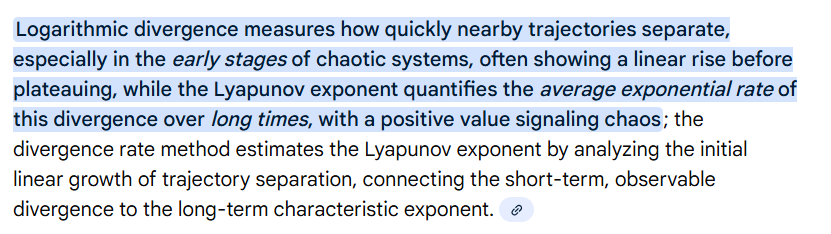